In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
file_path = '/content/drive/MyDrive/(11.02.2025) Квартиры 2014 кольцо.csv'
df = pd.read_csv(file_path)

**Загрузка и очистка данных**

In [5]:
# Проверка загрузки данных
df.head()

,Идентификатор,Комнатность,Новостройка,Метро.Район,Время.до.метро,Улица,Дом,Этаж,Этажность,Площадь.общая,Площадь.жилая,Площадь.кухни,Ценавруб.,Ценавдолл.,Ценавевро,Источник.получения,Дата.объявления,Контакты,На.сайте,Описание
0,24016418,1,Нет,Киевская,15.0,Сколковское ш.,36,4,9.0,21.0,16.0,4.0,3500000.0,99488,73466,Дом Сервис+,23.01.2014 5:20:30,"Тел.: 89150801223, http://www.7829980.ru, mail...",NaN,"Квартира 1-комн., общ.пл.-21, жил.пл.-16, кухн..."
1,23454997,1,Нет,Киевская,10.0,Матвеевская,26,5,5.0,31.0,18.0,6.0,4700000.0,133598,98654,Азбука Жилья,19.10.2013 5:05:10,"Тел.: +7 (495) 795-0569, http://http://www.azb...",NaN,"Квартира 1-комн., общ.пл.-31, жил.пл.-18, кухн..."
2,23697825,1,Нет,Марксистская,10.0,Бронницкая,4,5,5.0,32.0,18.0,7.0,5000000.0,145942,107770,ИНКОМ-Недвижимость,13.11.2013 12:20:37,"Тел.: +7(495)363-01-60, mailto:mk_tg@incom.ru",http://www.incom.ru/sale-realty/flats/lot/?L=в...,"Квартира 1-комн., общ.пл.-32.00, жил.пл.-18.00..."
3,23712199,1,Нет,Марксистская,5.0,Нижегородская,53,1,9.0,36.0,14.4,8.0,5350000.0,156158,115314,ИНКОМ-Недвижимость,16.11.2013 12:20:46,"Тел.: +7(495)363-01-60, mailto:mk_tg@incom.ru",http://www.incom.ru/sale-realty/flats/lot/?L=в...,"Квартира 1-комн., общ.пл.-36.00, жил.пл.-14.40..."
4,23701679,2,Нет,Таганская,10.0,Карачаровская 1-я,17,5,5.0,41.0,25.0,6.0,5350000.0,156158,115314,ИНКОМ-Недвижимость,14.11.2013 12:20:55,"Тел.: +7(495)363-01-60, mailto:mk_tg@incom.ru",http://www.incom.ru/sale-realty/flats/lot/?L=в...,"Квартира 2-комн., общ.пл.-41.00, жил.пл.-25.00..."


In [10]:
# Создаем копию исходного DataFrame для очистки
df_cleaned = df.copy()

# Список столбцов для удаления
columns_to_drop = [
    'Идентификатор', 'Улица', 'Дом', 'Источник.получения',
    'Дата.объявления', 'Контакты', 'На.сайте', 'Описание',
    'Ценавдолл.', 'Ценавевро'
]

# Создаем новый DataFrame без указанных столбцов
df_cleaned = df_cleaned.drop(columns=columns_to_drop)

# Проверяем результат
df_cleaned.head()

,Комнатность,Новостройка,Метро.Район,Время.до.метро,Этаж,Этажность,Площадь.общая,Площадь.жилая,Площадь.кухни,Ценавруб.
0,1,Нет,Киевская,15.0,4,9.0,21.0,16.0,4.0,3500000.0
1,1,Нет,Киевская,10.0,5,5.0,31.0,18.0,6.0,4700000.0
2,1,Нет,Марксистская,10.0,5,5.0,32.0,18.0,7.0,5000000.0
3,1,Нет,Марксистская,5.0,1,9.0,36.0,14.4,8.0,5350000.0
4,2,Нет,Таганская,10.0,5,5.0,41.0,25.0,6.0,5350000.0


In [11]:
# Проверка типов данных и общей информации о DataFrame
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2002 entries, 0 to 2001
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Комнатность     2002 non-null   int64  
 1   Новостройка     2002 non-null   object 
 2   Метро.Район     2002 non-null   object 
 3   Время.до.метро  1801 non-null   float64
 4   Этаж            1995 non-null   object 
 5   Этажность       1971 non-null   float64
 6   Площадь.общая   1999 non-null   float64
 7   Площадь.жилая   1843 non-null   float64
 8   Площадь.кухни   891 non-null    float64
 9   Ценавруб.       2002 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 156.5+ KB


In [21]:
# Преобразуем столбец "Этаж" в строковый тип (если это еще не сделано)
df_cleaned['Этаж'] = df_cleaned['Этаж'].astype(str)

# Создаем множество уникальных символов для каждого значения в столбце "Этаж"
unique_chars = df_cleaned['Этаж'].apply(lambda x: set(str(x)))

# Выводим уникальные символы
print("Уникальные символы в столбце 'Этаж':")
print(unique_chars)

# Находим строки, которые содержат нечисловые символы
non_numeric_values = df_cleaned[df_cleaned['Этаж'].apply(lambda x: not x.isnumeric())]
print("\nСтроки с нечисловыми значениями в столбце 'Этаж':")
print(non_numeric_values['Этаж'])

Уникальные символы в столбце 'Этаж':
0          {4}
1          {5}
2          {5}
3          {1}
4          {5}
         ...  
1997    {2, 1}
1998       {7}
1999    {4, 3}
2000    {4, 3}
2001       {1}
Name: Этаж, Length: 2002, dtype: object

Строки с нечисловыми значениями в столбце 'Этаж':
23        ?
142       ?
560       ?
616     nan
808     nan
960       ?
1397    nan
1441    nan
1695    nan
1800    nan
1904    nan
Name: Этаж, dtype: object


In [22]:
# Заменяем лишние значения на numpy.nan
df_cleaned['Этаж'] = df_cleaned['Этаж'].replace({'?': np.nan, 'nan': np.nan})

# Преобразуем столбец в числовой тип
df_cleaned['Этаж'] = pd.to_numeric(df_cleaned['Этаж'], errors='coerce')

In [23]:
print("Информация о типах данных всех полей:")
df_cleaned.info()

Информация о типах данных всех полей:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2002 entries, 0 to 2001
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Комнатность     2002 non-null   int64  
 1   Новостройка     2002 non-null   object 
 2   Метро.Район     2002 non-null   object 
 3   Время.до.метро  1801 non-null   float64
 4   Этаж            1991 non-null   float64
 5   Этажность       1971 non-null   float64
 6   Площадь.общая   1999 non-null   float64
 7   Площадь.жилая   1843 non-null   float64
 8   Площадь.кухни   891 non-null    float64
 9   Ценавруб.       2002 non-null   float64
dtypes: float64(7), int64(1), object(2)
memory usage: 156.5+ KB


In [24]:
print("Количество пропущенных значений в столбце 'Этаж':", df_cleaned['Этаж'].isnull().sum())

# Если пропущенных значений нет, преобразуем в int64
if df_cleaned['Этаж'].isnull().sum() == 0:
    df_cleaned['Этаж'] = df_cleaned['Этаж'].astype(int)
    print("\nТип данных столбца 'Этаж' после преобразования:", df_cleaned['Этаж'].dtype)
else:
    print("\nВ столбце 'Этаж' есть пропущенные значения. Удалите или заполните их перед преобразованием.")

Количество пропущенных значений в столбце 'Этаж': 11

В столбце 'Этаж' есть пропущенные значения. Удалите или заполните их перед преобразованием.


In [25]:
# Удаление дубликатов
df_cleaned = df_cleaned.drop_duplicates()

# Проверка результата
print("Количество строк после удаления дубликатов:", len(df_cleaned))

Количество строк после удаления дубликатов: 1599


**Работа с пропусками**

In [26]:
!pip install missingno

Количество пропусков в каждом столбце:
Комнатность         0
Новостройка         0
Метро.Район         0
Время.до.метро    201
Этаж               11
Этажность          31
Площадь.общая       3
Площадь.жилая     159
Площадь.кухни     714
Ценавруб.           0
dtype: int64


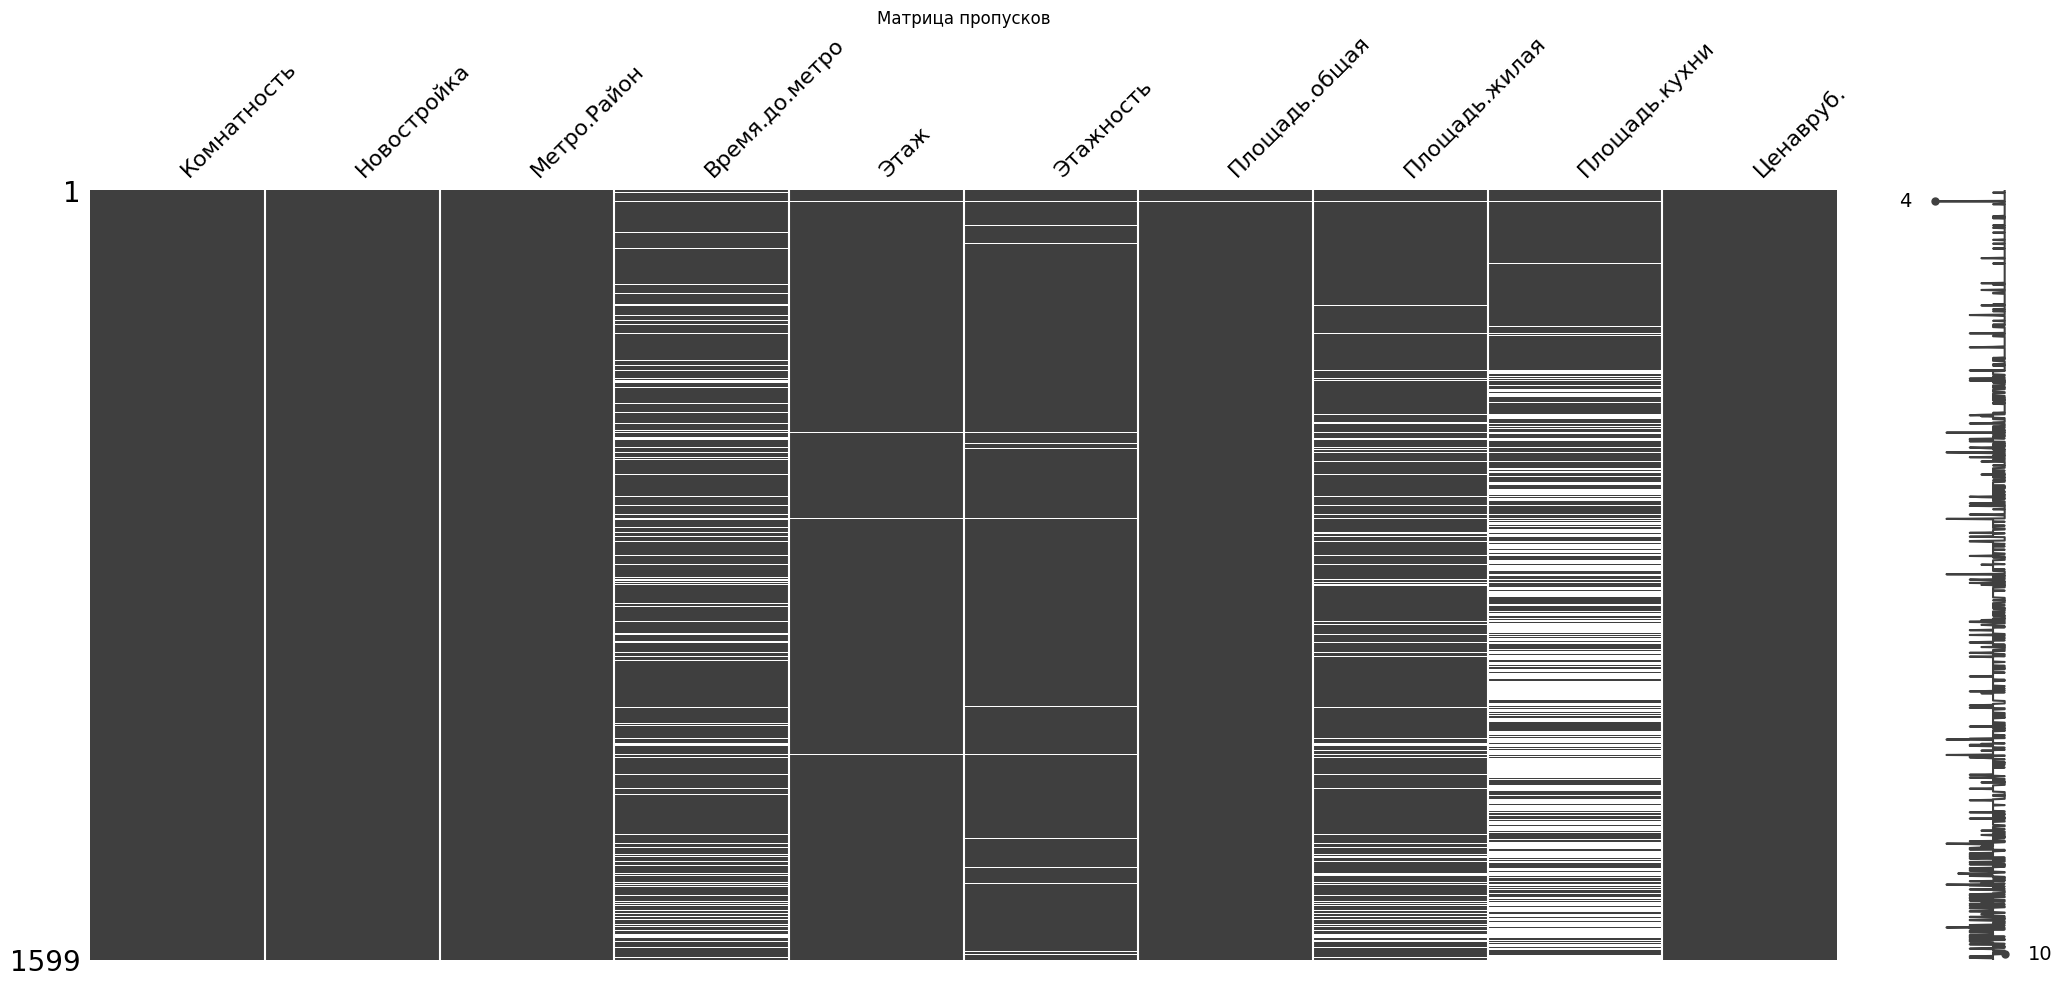

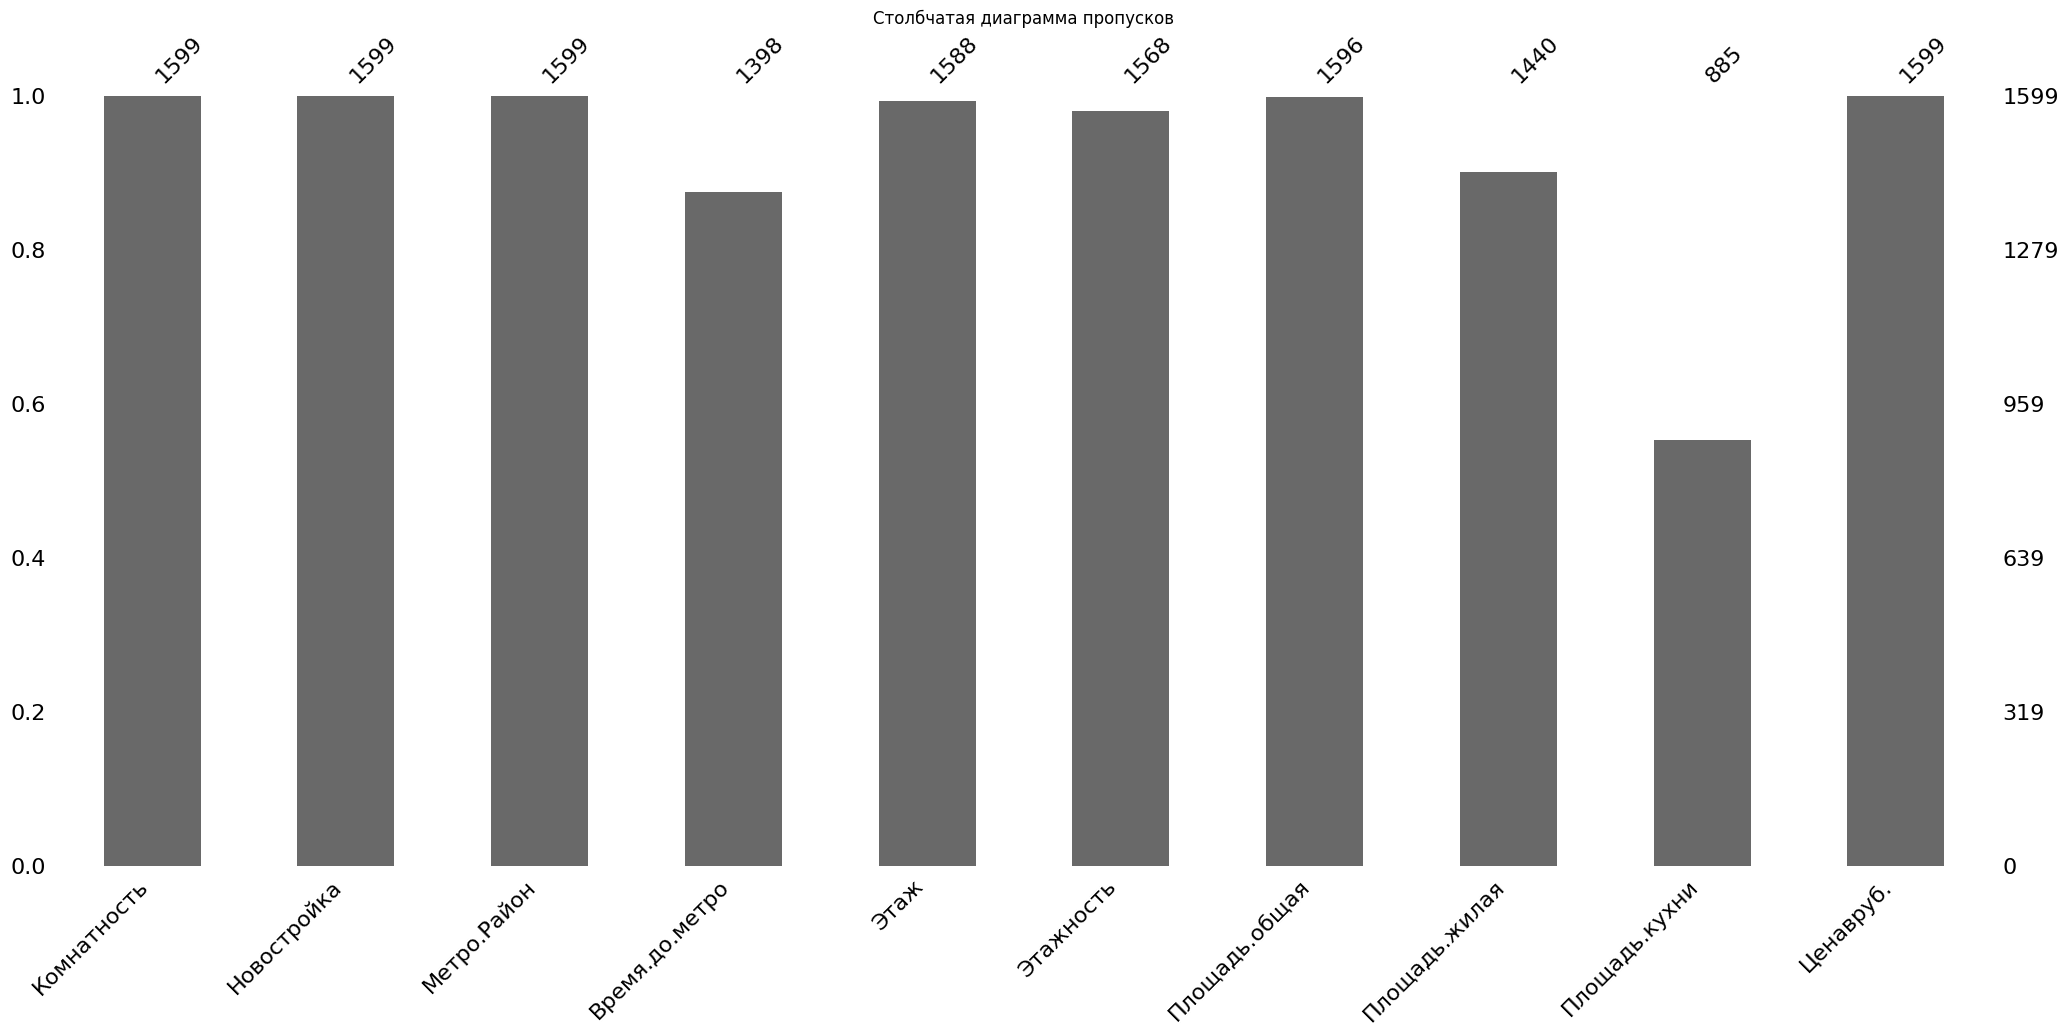

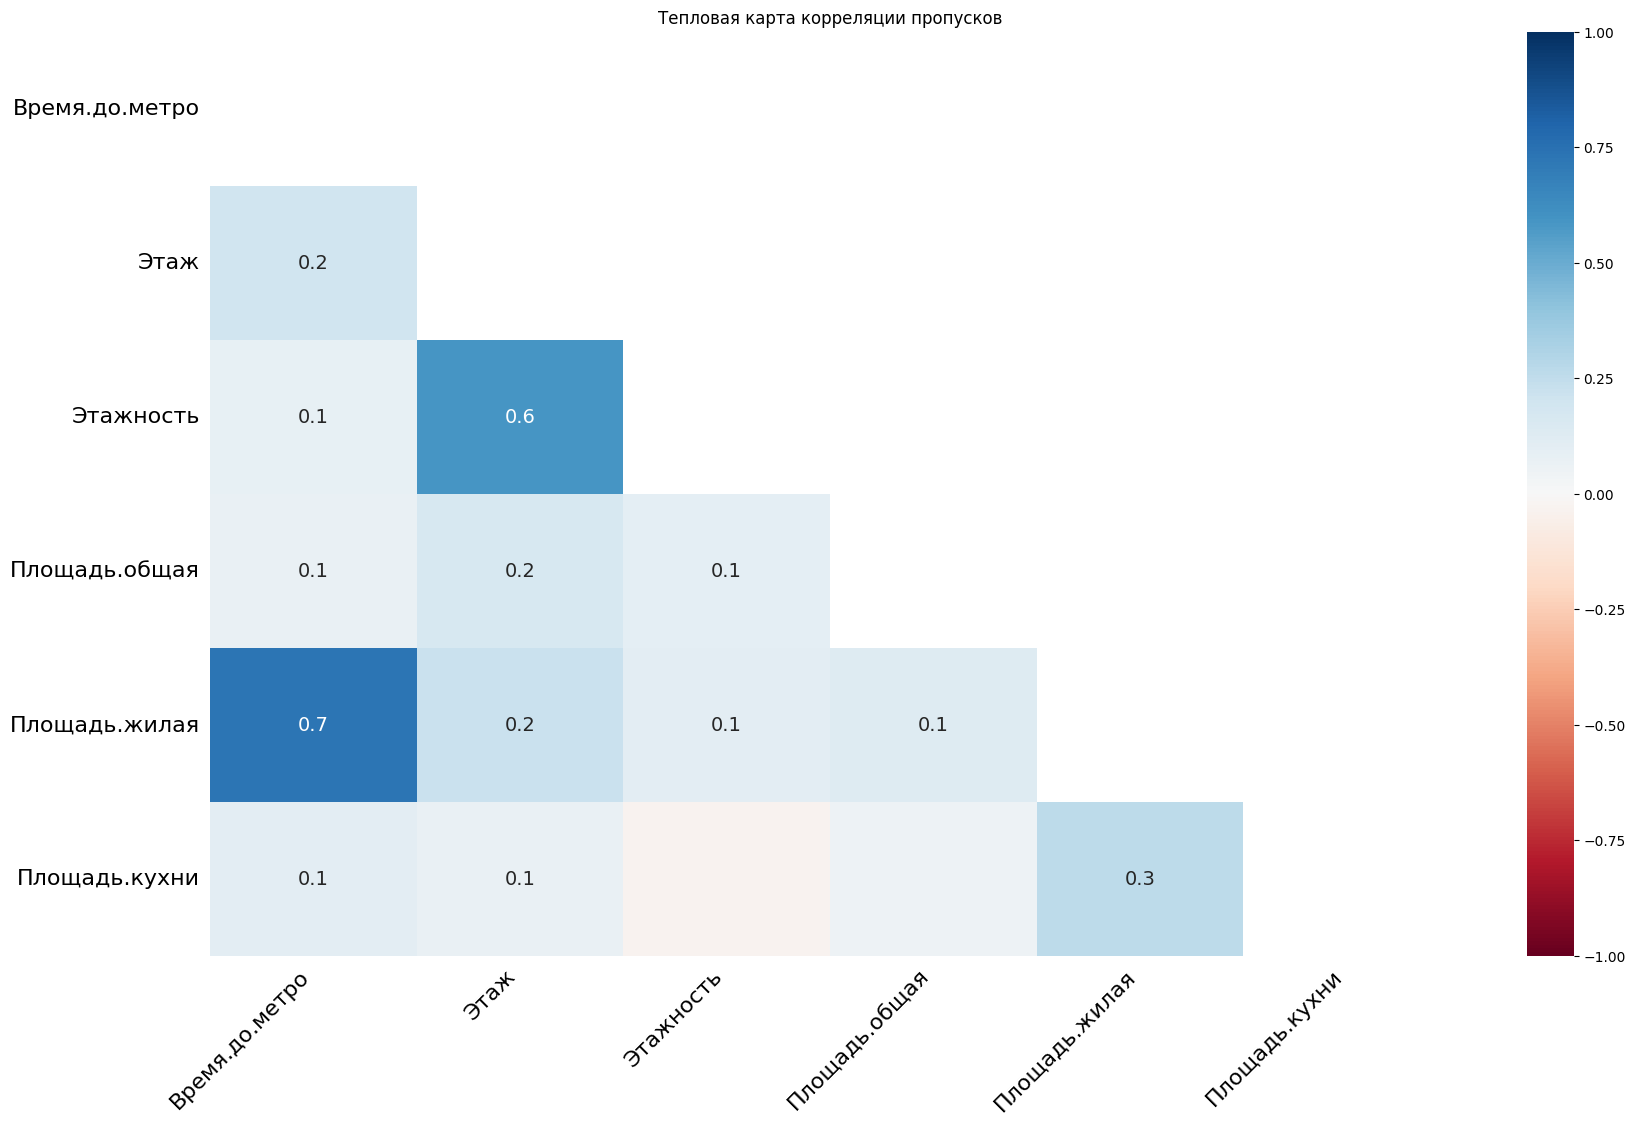

In [27]:
# Подсчет пропусков в каждом столбце
missing_values = df_cleaned.isna().sum()
print("Количество пропусков в каждом столбце:")
print(missing_values)

# Визуализация пропусков с помощью missingno
import missingno as msno
import matplotlib.pyplot as plt

# Матрица пропусков
msno.matrix(df_cleaned)
plt.title("Матрица пропусков")
plt.show()

# Столбчатая диаграмма пропусков
msno.bar(df_cleaned)
plt.title("Столбчатая диаграмма пропусков")
plt.show()

# Тепловая карта корреляции пропусков
msno.heatmap(df_cleaned)
plt.title("Тепловая карта корреляции пропусков")
plt.show()

Поля 'Площадь.общая' и
'Площадь.жилая' сильно коррелируют
между собой. Площадь жилая содержит больше пропусков, чем площадь общая, удалим его.

In [28]:
# Удаляем столбец 'Площадь.жилая', так как в нем больше пропусков
df_cleaned = df_cleaned.drop(columns=['Площадь.жилая'])

# Проверяем результат
print("Столбцы после удаления 'Площадь.жилая':")
print(df_cleaned.columns)

Столбцы после удаления 'Площадь.жилая':
Index(['Комнатность', 'Новостройка', 'Метро.Район', 'Время.до.метро', 'Этаж',
       'Этажность', 'Площадь.общая', 'Площадь.кухни', 'Ценавруб.'],
      dtype='object')


In [29]:
# Вычисляем медианное значение для столбца 'Время.до.метро'
median_time_to_metro = df_cleaned['Время.до.метро'].median()
print("Медианное значение для 'Время.до.метро':", median_time_to_metro)

# Заполняем пропуски медианным значением
df_cleaned['Время.до.метро'] = df_cleaned['Время.до.метро'].fillna(median_time_to_metro)

# Проверяем результат
print("Количество пропусков в 'Время.до.метро' после заполнения:",
      df_cleaned['Время.до.метро'].isna().sum())

Медианное значение для 'Время.до.метро': 10.0
Количество пропусков в 'Время.до.метро' после заполнения: 0


In [30]:
# Вычисляем средние значения площади кухни для каждой группы по количеству комнат
mean_kitchen_by_rooms = df_cleaned.groupby('Комнатность')['Площадь.кухни'].transform('mean')

# Заполняем пропуски в 'Площадь.кухни' средними значениями по количеству комнат
df_cleaned['Площадь.кухни'] = df_cleaned['Площадь.кухни'].fillna(mean_kitchen_by_rooms)

# Проверяем результат
print("Количество пропусков в 'Площадь.кухни' после заполнения:",
      df_cleaned['Площадь.кухни'].isna().sum())

Количество пропусков в 'Площадь.кухни' после заполнения: 6


In [31]:
print("Количество пропусков в каждом столбце:")
print(df_cleaned.isna().sum())

Количество пропусков в каждом столбце:
Комнатность        0
Новостройка        0
Метро.Район        0
Время.до.метро     0
Этаж              11
Этажность         31
Площадь.общая      3
Площадь.кухни      6
Ценавруб.          0
dtype: int64


In [32]:
# Удаляем строки, в которых есть пропуски
df_cleaned = df_cleaned.dropna()

# Проверяем результат
print("\nКоличество пропусков после удаления строк:")
print(df_cleaned.isna().sum())


Количество пропусков после удаления строк:
Комнатность       0
Новостройка       0
Метро.Район       0
Время.до.метро    0
Этаж              0
Этажность         0
Площадь.общая     0
Площадь.кухни     0
Ценавруб.         0
dtype: int64


**Работа с выбросами**

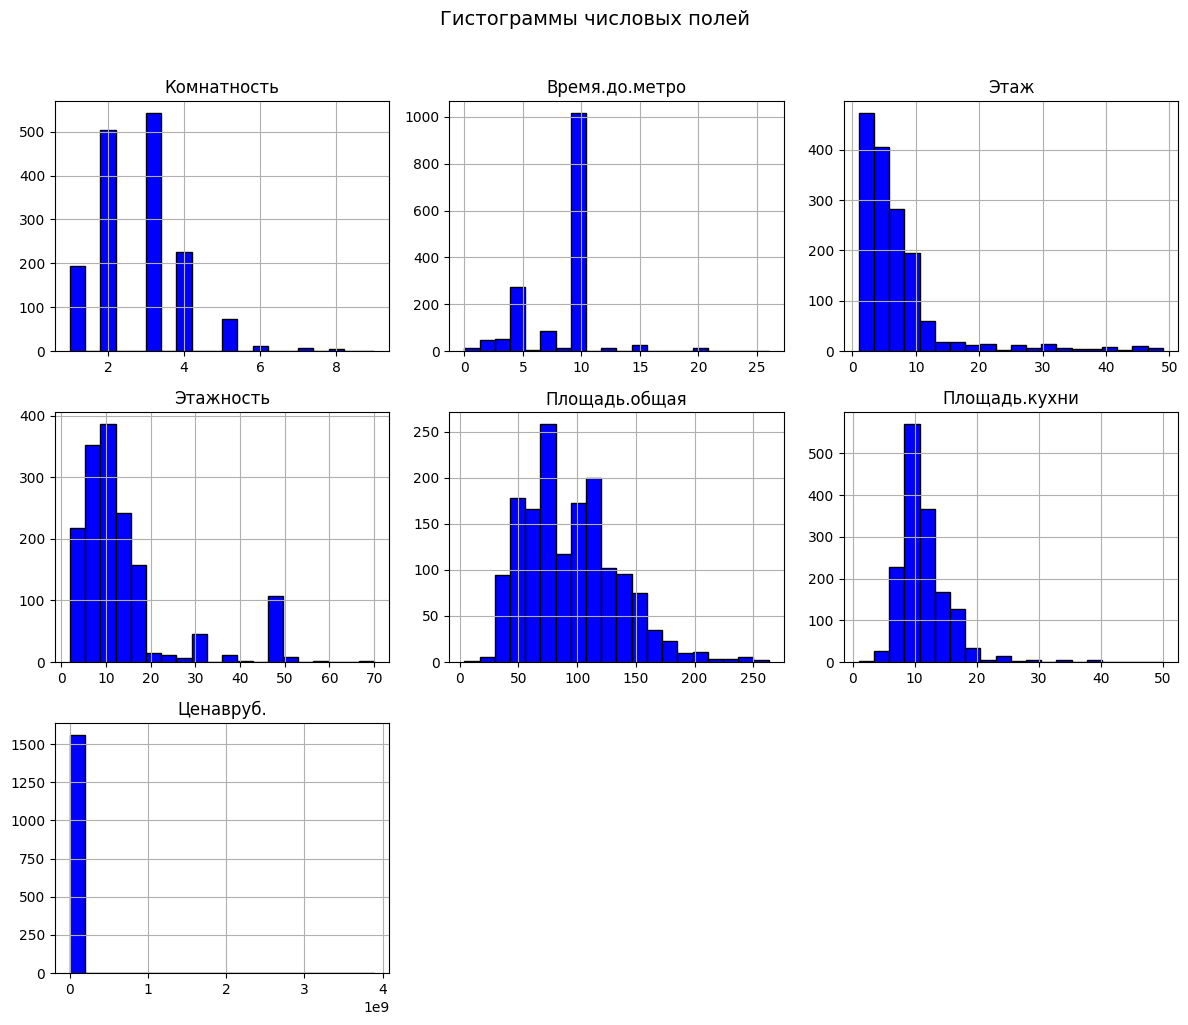

In [33]:
import matplotlib.pyplot as plt

# Построение гистограмм для всех числовых полей
df_cleaned.hist(figsize=(12, 10), bins=20, color='blue', edgecolor='black')
plt.suptitle("Гистограммы числовых полей", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Поле ‘Ценавруб.’ распределено
очень неравномерно. Построим ящик с усами
(boxplot) для этого поля.

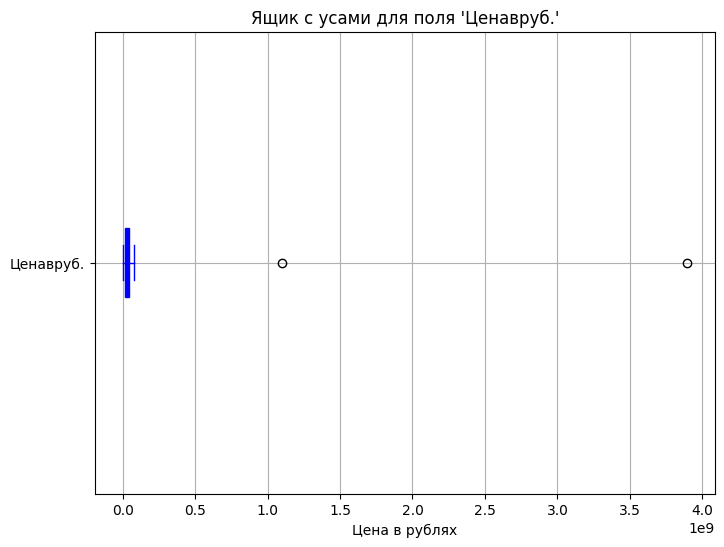

In [34]:
# Построение boxplot для поля 'Ценавруб.'
plt.figure(figsize=(8, 6))  # Задаем размер графика
df_cleaned.boxplot(column='Ценавруб.', vert=False, color='blue', patch_artist=True)
plt.title("Ящик с усами для поля 'Ценавруб.'")
plt.xlabel("Цена в рублях")
plt.show()

Видим несколько выбросов

In [35]:
# Вычисляем Q1, Q3 и IQR для поля 'Ценавруб.'
Q1 = df_cleaned['Ценавруб.'].quantile(0.25)
Q3 = df_cleaned['Ценавруб.'].quantile(0.75)
IQR = Q3 - Q1

# Определяем граничное значение для выбросов
upper_bound = Q3 + 1.5 * IQR
print("Граничное значение для выбросов:", upper_bound)

# Фильтруем строки с выбросами
outliers = df_cleaned[df_cleaned['Ценавруб.'] > upper_bound]

# Выводим строки с выбросами
print("\nСтроки с выбросами в поле 'Ценавруб.':")
print(outliers)

Граничное значение для выбросов: 80137500.0

Строки с выбросами в поле 'Ценавруб.':
      Комнатность Новостройка    Метро.Район  Время.до.метро  Этаж  Этажность  \
1999            5         Нет       Киевская            10.0  34.0       47.0   
2001            4          Да  Парк культуры            10.0   1.0        6.0   

      Площадь.общая  Площадь.кухни     Ценавруб.  
1999          241.0      16.490741  1.102189e+09  
2001          251.0      14.317123  3.893019e+09  


Просмотрев эти строки, мы убедились, что это,
действительно, нетипичные объекты.

Количество строк после удаления выбросов: 1558


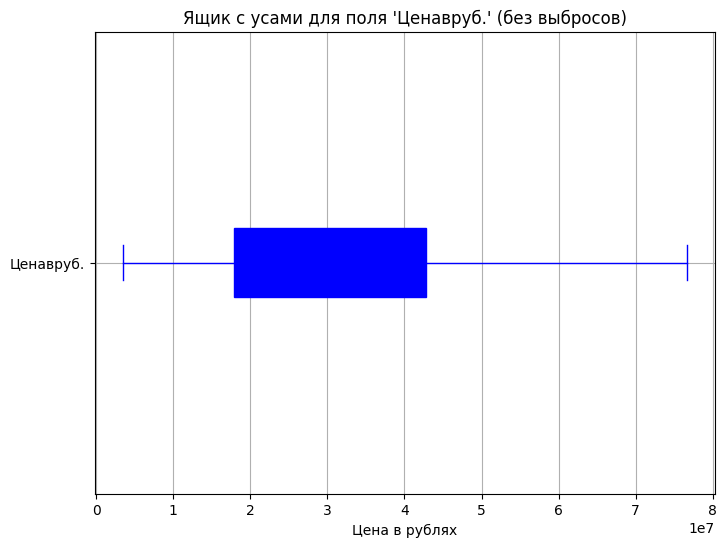

In [36]:
# Удаляем строки с выбросами
df_cleaned = df_cleaned[df_cleaned['Ценавруб.'] <= upper_bound]

# Проверяем результат
print("Количество строк после удаления выбросов:", len(df_cleaned))

# Построение boxplot для поля 'Ценавруб.' после удаления выбросов
plt.figure(figsize=(8, 6))  # Задаем размер графика
df_cleaned.boxplot(column='Ценавруб.', vert=False, color='blue', patch_artist=True)
plt.title("Ящик с усами для поля 'Ценавруб.' (без выбросов)")
plt.xlabel("Цена в рублях")
plt.show()

**Кодирование категориальных переменных**

In [37]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)

encoded_data = encoder.fit_transform(df_cleaned[['Новостройка', 'Метро.Район']])

encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(['Новостройка', 'Метро.Район']))

df_encoded = pd.concat([df_cleaned.drop(['Новостройка', 'Метро.Район'], axis=1), encoded_df], axis=1)

print("Первые 5 строк после кодирования:")
print(df_encoded.head())

Первые 5 строк после кодирования:
   Комнатность  Время.до.метро  Этаж  Этажность  Площадь.общая  Площадь.кухни  \
0          1.0            15.0   4.0        9.0           21.0            4.0   
1          1.0            10.0   5.0        5.0           31.0            6.0   
2          1.0            10.0   5.0        5.0           32.0            7.0   
3          1.0             5.0   1.0        9.0           36.0            8.0   
4          2.0            10.0   5.0        5.0           41.0            6.0   

   Ценавруб.  Новостройка_Нет  Метро.Район_Арбатская  Метро.Район_Баррикадная  \
0  3500000.0              1.0                    0.0                      0.0   
1  4700000.0              1.0                    0.0                      0.0   
2  5000000.0              1.0                    0.0                      0.0   
3  5350000.0              1.0                    0.0                      0.0   
4  5350000.0              1.0                    0.0                      

In [38]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1893 entries, 0 to 1557
Data columns (total 49 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Комнатность                        1558 non-null   float64
 1   Время.до.метро                     1558 non-null   float64
 2   Этаж                               1558 non-null   float64
 3   Этажность                          1558 non-null   float64
 4   Площадь.общая                      1558 non-null   float64
 5   Площадь.кухни                      1558 non-null   float64
 6   Ценавруб.                          1558 non-null   float64
 7   Новостройка_Нет                    1558 non-null   float64
 8   Метро.Район_Арбатская              1558 non-null   float64
 9   Метро.Район_Баррикадная            1558 non-null   float64
 10  Метро.Район_Белорусская            1558 non-null   float64
 11  Метро.Район_Библиотека им. Ленина  1558 non-null   float64
 1

In [41]:
# Удаляем текстовые поля
text_columns = df_cleaned.select_dtypes(include=['object']).columns
df_cleaned = df_cleaned.drop(columns=text_columns)

# Применяем One-Hot Encoding
df_encoded = pd.get_dummies(df_cleaned, drop_first=True)

# Проверяем результат
print("Столбцы после One-Hot Encoding:")
print(df_encoded.columns)

# Проверяем типы данных
print("\nТипы данных всех столбцов:")
print(df_encoded.dtypes)

Столбцы после One-Hot Encoding:
Index(['Комнатность', 'Время.до.метро', 'Этаж', 'Этажность', 'Площадь.общая',
       'Площадь.кухни', 'Ценавруб.'],
      dtype='object')

Типы данных всех столбцов:
Комнатность         int64
Время.до.метро    float64
Этаж              float64
Этажность         float64
Площадь.общая     float64
Площадь.кухни     float64
Ценавруб.         float64
dtype: object
Столбцы после One-Hot Encoding:
Index(['Комнатность', 'Время.до.метро', 'Этаж', 'Этажность', 'Площадь.общая',
       'Площадь.кухни', 'Ценавруб.'],
      dtype='object')

Типы данных всех столбцов:
Комнатность         int64
Время.до.метро    float64
Этаж              float64
Этажность         float64
Площадь.общая     float64
Площадь.кухни     float64
Ценавруб.         float64
dtype: object


**Формирование обучающего и тестового множества**

In [43]:
from sklearn.model_selection import train_test_split

# Входные данные (X) — все столбцы, кроме 'Ценавруб.'
X = df_encoded.drop(columns=['Ценавруб.'])

# Выходные данные (y) — столбец 'Ценавруб.'
y = df_encoded['Ценавруб.']

# Разделяем данные на обучающую и тестовую выборки (80% на обучение, 20% на тестирование)
X_learn, X_test, y_learn, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Проверяем размеры выборок
print("Размеры обучающей выборки (X_learn, y_learn):", X_learn.shape, y_learn.shape)
print("Размеры тестовой выборки (X_test, y_test):", X_test.shape, y_test.shape)

Размеры обучающей выборки (X_learn, y_learn): (1246, 6) (1246,)
Размеры тестовой выборки (X_test, y_test): (312, 6) (312,)


**Выбор метрик**

In [44]:
# Обучаем модель (пример)
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_learn, y_learn)

# Делаем предсказания на тестовых данных
y_pred = model.predict(X_test)

# Вычисляем метрики
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Выводим результаты
print("Средняя абсолютная ошибка (MAE):", mae)
print("Среднеквадратичная ошибка (MSE):", mse)
print("Коэффициент детерминации (R²):", r2)

NameError: name 'mean_absolute_error' is not defined